# Why the $S_{11}$ / $S_{22}$ dips matter when measuring $Q$

**Split-ring resonator lab: coupling correction, with all the math**

## The short answer

Your TA and this analysis are both right. They answer two different questions.

| Goal | What you want | Why |
|---|---|---|
| Get as much power as possible **into** the resonator (TA's point) | A **deep** reflection dip | Less power reflected means more power absorbed |
| Measure the resonator's **own** $Q$ (this lab) | A **shallow** dip, or a deep dip that you correct for | The port that lets power in also lets stored energy leak back out, which broadens the peak |

The dip depth tells you how strongly the loop is coupled. Strong coupling is good for power transfer, but it adds a loss channel that lowers the $Q$ you measure. The $S_{11}$ and $S_{22}$ dips let you work out how much of the measured linewidth is caused by the loops, and remove it:

$$\boxed{Q_0 = Q_L\,(1+\beta_1+\beta_2) = \frac{2\,Q_L}{s_1+s_2}}$$

Here $Q_L$ is the $Q$ you fit from the $S_{21}$ peak, and $s_1$, $s_2$ are the linear magnitudes of $S_{11}$ and $S_{22}$ at resonance, measured relative to the off-resonance baseline. The rest of this notebook derives that formula, tests it on a simulated resonator, and applies it to your runs.

## 1. Physical intuition

A coupling loop is a door, and doors work in both directions.

- When the generator drives the loop, the loop's magnetic flux threads the ring and pushes energy **in**.
- By the same mutual inductance, the ring's oscillating flux threads the loop and drives a current into the 50 Ω cable. That is stored energy flowing **out**.

So from the ring's point of view, each loop looks like an extra resistor in series with its own resistance. The more strongly the loop is coupled, the bigger that extra resistor, and the faster the stored energy drains away. A resonator that loses energy faster has a wider peak, which means a lower $Q$.

The reflection dip measures the same coupling from the cable's side. Far from resonance the ring does nothing and the loop reflects everything. At resonance the ring absorbs some of the incident wave, so less comes back, and you see a dip. A deeper dip means more absorption, which means a bigger door, which means more loading.

That is why the two statements are consistent:

- **TA:** a big dip means power is getting into the resonator. True.
- **This analysis:** a big dip means the port is loading the resonator heavily, so the measured $Q$ is well below the resonator's own $Q$. Also true.

## 2. Derivation

### Step 1: the bare resonator

Model the ring as a series LRC circuit (Bobowski, Fig. 1d). Its impedance is

$$Z_r(\omega) = R + j\omega L + \frac{1}{j\omega C},$$

with resonance at $\omega_0 = 1/\sqrt{LC}$. The **unloaded** quality factor is the one in the paper's Eq. (4):

$$Q_0 = \frac{\omega_0 L}{R}.$$

This is the number the paper compares against $r_0/\delta$.

### Step 2: add one coupling loop

A loop on the end of a cable with characteristic impedance $Z_0 = 50\ \Omega$ couples to the ring through a mutual inductance $M$. Let $I_1$ be the loop current and $I_r$ the ring current. Neglecting the loop's small self-inductance, Kirchhoff's voltage law for the two circuits gives

$$V_1 = j\omega M\, I_r, \qquad 0 = Z_r\, I_r + j\omega M\, I_1 .$$

Solve the second equation for $I_r$ and substitute into the first:

$$I_r = -\frac{j\omega M}{Z_r} I_1 \quad\Longrightarrow\quad V_1 = \frac{(\omega M)^2}{Z_r}\, I_1 .$$

So the impedance the cable sees looking into the loop is

$$Z_{\text{in}} = \frac{V_1}{I_1} = \frac{(\omega M)^2}{Z_r}.$$

### Step 3: what the ring sees

Run the same argument in the other direction. The ring's current induces a voltage in the loop, which drives current into the cable's $Z_0$. From the ring's side, the loop plus cable appears as a series resistance

$$R_c = \frac{(\omega M)^2}{Z_0}.$$

Define the **coupling coefficient** as the ratio of this added resistance to the ring's own resistance:

$$\beta \equiv \frac{R_c}{R} = \frac{(\omega_0 M)^2}{Z_0 R}.$$

- $\beta \ll 1$: undercoupled (weak). The port barely disturbs the ring.
- $\beta = 1$: critically coupled. The port dissipates as much as the ring does.
- $\beta > 1$: overcoupled. The port is the dominant loss.

### Step 4: the loaded $Q$

With two loops, the total series resistance in the ring is $R + R_{c1} + R_{c2} = R\,(1+\beta_1+\beta_2)$. The linewidth you measure is set by this total, so

$$Q_L = \frac{\omega_0 L}{R\,(1+\beta_1+\beta_2)} = \frac{Q_0}{1+\beta_1+\beta_2}.$$

Equivalently, loss rates add:

$$\frac{1}{Q_L} = \frac{1}{Q_0} + \frac{1}{Q_{e1}} + \frac{1}{Q_{e2}}, \qquad Q_{ei} = \frac{Q_0}{\beta_i}.$$

This is the same "inverse $Q$'s add" rule as the paper's Eq. (14). The loops are just two more loss mechanisms.

### Step 5: the reflection dip

Look into port 1 at resonance, where $Z_r = R$. Port 2's loop is still attached, so the ring's resistance as seen from port 1 is $R + R_{c2} = R\,(1+\beta_2)$. Using Step 2,

$$Z_{\text{in},1} = \frac{(\omega_0 M_1)^2}{R\,(1+\beta_2)} = Z_0\,\frac{\beta_1}{1+\beta_2}.$$

The reflection coefficient is

$$S_{11} = \frac{Z_{\text{in},1} - Z_0}{Z_{\text{in},1} + Z_0} = \frac{\beta_1 - 1 - \beta_2}{1+\beta_1+\beta_2}.$$

By symmetry,

$$S_{22} = \frac{\beta_2 - 1 - \beta_1}{1+\beta_1+\beta_2}, \qquad S_{21} = \frac{2\sqrt{\beta_1\beta_2}}{1+\beta_1+\beta_2}.$$

Far from resonance $Z_r$ is huge, $Z_{\text{in}} \to 0$, and $|S_{11}| \to 1$: everything reflects. That is the flat baseline. The dip is the drop from that baseline to the on-resonance value.

### Step 6: invert to get $Q_0$

Let $D = 1+\beta_1+\beta_2$, and let $s_1 = |S_{11}|$, $s_2 = |S_{22}|$ at resonance (linear, relative to baseline). If both ports are undercoupled, the numerators above are negative, so

$$s_1 = \frac{1+\beta_2-\beta_1}{D}, \qquad s_2 = \frac{1+\beta_1-\beta_2}{D}.$$

Add them. The $\beta$'s cancel in the numerator:

$$s_1 + s_2 = \frac{2}{D} \quad\Longrightarrow\quad D = \frac{2}{s_1+s_2}.$$

Since $Q_0 = Q_L D$,

$$\boxed{Q_0 = \frac{2\,Q_L}{s_1+s_2}}, \qquad \beta_i = \frac{D\,(1-s_i)}{2}.$$

Check the limits. If neither port shows a dip, $s_1 = s_2 = 1$ and $Q_0 = Q_L$, so no correction is needed. If the dips are deep, $s_1 + s_2$ is small and the correction is large.

### Step 7: the TA's point, in the same equations

For a single port, the fraction of incident power absorbed at resonance is

$$\frac{P_\text{abs}}{P_\text{inc}} = 1 - |S_{11}|^2 = 1 - \left(\frac{1-\beta}{1+\beta}\right)^2 = \frac{4\beta}{(1+\beta)^2}.$$

This is maximized at $\beta = 1$, where the dip is infinitely deep and all the power goes in. That is exactly what the TA is describing. At that same point,

$$Q_L = \frac{Q_0}{1+\beta} = \frac{Q_0}{2}.$$

So the coupling that gives perfect power transfer also halves the measured $Q$. Best power transfer and least disturbance of the resonator are opposite ends of the same knob.

### Step 8: a caveat about magnitude-only data

The dip depth depends on $|1-\beta|/(1+\beta)$, which gives the same value for $\beta$ and $1/\beta$. A 6 dB dip could be an undercoupled port or an overcoupled one. If port 2 were overcoupled, the sign of its numerator flips and the formula becomes $Q_0 = 2Q_L/(s_1 - s_2)$.

To tell them apart without phase data, pull the loop back. If the dip gets shallower straight away, you were undercoupled. If it gets deeper first, you were overcoupled.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 3. The trade-off in one picture

Single port, as a function of coupling $\beta$: the dip depth, the fraction of power absorbed, and how much the measured $Q$ is pulled down.

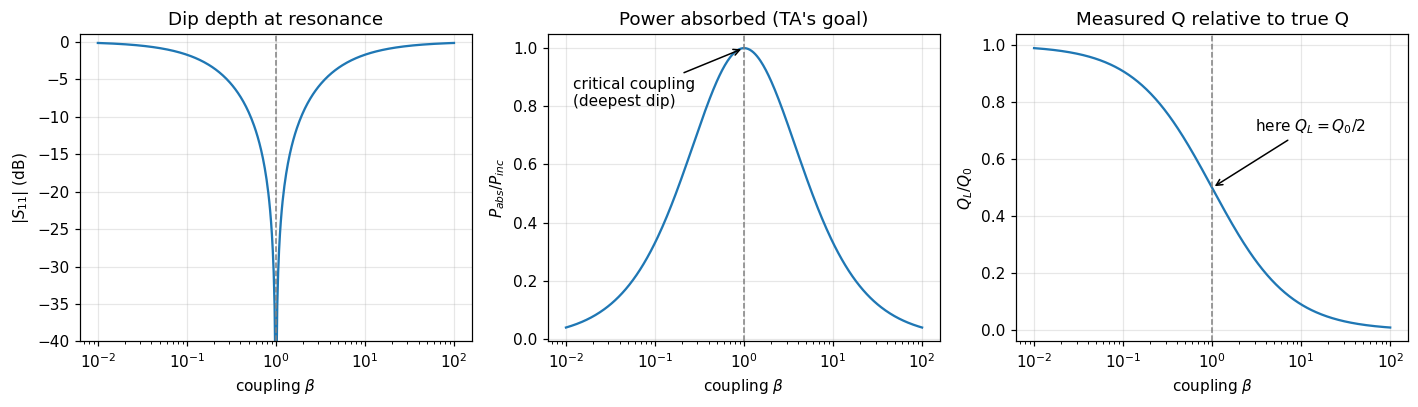

In [3]:
beta = np.logspace(-2, 2, 400)

dip_dB   = 20*np.log10(np.abs(1 - beta)/(1 + beta) + 1e-12)   # reflection at resonance
absorbed = 4*beta/(1 + beta)**2                               # fraction of power absorbed
QL_ratio = 1/(1 + beta)                                       # Q_L / Q_0

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))

ax[0].semilogx(beta, dip_dB)
ax[0].set_ylim(-40, 1)
ax[0].set_title("Dip depth at resonance")
ax[0].set_xlabel(r"coupling $\beta$"); ax[0].set_ylabel(r"$|S_{11}|$ (dB)")

ax[1].semilogx(beta, absorbed)
ax[1].set_title("Power absorbed (TA's goal)")
ax[1].set_xlabel(r"coupling $\beta$"); ax[1].set_ylabel(r"$P_{abs}/P_{inc}$")

ax[2].semilogx(beta, QL_ratio)
ax[2].set_title("Measured Q relative to true Q")
ax[2].set_xlabel(r"coupling $\beta$"); ax[2].set_ylabel(r"$Q_L/Q_0$")

for a in ax:
    a.axvline(1, ls="--", c="gray", lw=1)
ax[1].annotate("critical coupling\n(deepest dip)", xy=(1, 1), xytext=(0.012, 0.8),
               arrowprops=dict(arrowstyle="->"))
ax[2].annotate(r"here $Q_L = Q_0/2$", xy=(1, 0.5), xytext=(3, 0.7),
               arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()

Reading the three panels together:

- **Left and middle:** the deepest dip ($\beta = 1$) is where all the power is absorbed. This is the TA's statement.
- **Right:** at that same point the measured $Q$ is only half the true value. For a $Q$ measurement you either work at the far left ($\beta \ll 1$, tiny dip, $Q_L \approx Q_0$), or you measure the dip and correct for it.
- **Left:** the dip curve is symmetric about $\beta = 1$ on this log axis. That is the under/overcoupled ambiguity from Step 8.

## 4. Test on a simulated resonator

To check that the correction really works, build the full two-port circuit from Section 2, generate $S_{11}$, $S_{21}$, $S_{22}$ sweeps with a **known** $Q_0$, then analyze them the way you would in the lab: fit the $S_{21}$ peak for $Q_L$, read the two dips, and apply $Q_0 = 2Q_L/(s_1+s_2)$.

The $Z$-matrix of the ring with two loops follows from Step 2 with two ports:

$$Z_{ij} = \frac{\omega^2 M_i M_j}{Z_r(\omega)},$$

and the $S$-parameters come from the standard conversion $S = (Z - Z_0)(Z + Z_0)^{-1}$.

In [4]:
Z0 = 50.0
L_ring = 4e-7*np.pi * np.pi*(1.746e-2)**2 / 10.16e-2      # Eq. (1) of the paper, ~11.8 nH

def sparams(f_MHz, f0_MHz, Q0, b1, b2, cable_loss_dB=1.1):
    '''Two-port S-parameters (complex) of a series LRC ring with two coupling loops.
    b1, b2 are the coupling coefficients beta_1, beta_2 at resonance.
    cable_loss_dB is the round-trip cable loss seen on the reflection traces.'''
    w, w0 = 2*np.pi*f_MHz*1e6, 2*np.pi*f0_MHz*1e6
    C  = 1/(w0**2 * L_ring)
    R  = w0*L_ring/Q0
    Zr = R + 1j*w*L_ring + 1/(1j*w*C)
    k1 = np.sqrt(b1*R*Z0) * w/w0            # omega*M1
    k2 = np.sqrt(b2*R*Z0) * w/w0            # omega*M2
    Z11, Z22, Z12 = k1**2/Zr, k2**2/Zr, k1*k2/Zr
    det = (Z11 + Z0)*(Z22 + Z0) - Z12**2
    S11 = ((Z11 - Z0)*(Z22 + Z0) - Z12**2)/det
    S22 = ((Z11 + Z0)*(Z22 - Z0) - Z12**2)/det
    S21 = 2*Z12*Z0/det
    a = 10**(-cable_loss_dB/20)             # cable loss scales the reflected wave
    return a*S11, np.sqrt(a)*S21, a*S22

def lorentz(f, A, f0, Q):
    '''Erratum form of the paper's Eq. (7), written in terms of Q.'''
    return A/np.sqrt(1 + Q**2*(f/f0 - f0/f)**2)

def analyze(f, S11_dB, S21_dB, S22_dB, label="", verbose=True):
    '''Lab-style analysis of magnitude-only data in dB. Returns a dict of results.'''
    m11, m21, m22 = 10**(S11_dB/20), 10**(S21_dB/20), 10**(S22_dB/20)

    # 1) loaded Q from the transmission peak
    k = m21.argmax()
    p, _ = curve_fit(lorentz, f, m21, p0=[m21[k], f[k], 300],
                     bounds=([0, f[k]-2, 5], [5*m21[k], f[k]+2, 1e5]))
    A, f0, QL = p
    fwhm = f0/QL

    # 2) dips relative to the off-resonance baseline
    def rel_dip(m):
        mask = np.abs(f - f0) > 4*fwhm                      # baseline points only
        base = np.polyval(np.polyfit(f[mask], m[mask], 2), f)
        return (m/base)[np.abs(f - f0) < 0.5*fwhm].min()    # linear, 1 = no dip
    s1, s2 = rel_dip(m11), rel_dip(m22)

    # 3) coupling correction
    D = 2/(s1 + s2)
    out = dict(label=label, f0=f0, QL=QL, s1=s1, s2=s2,
               dip1_dB=20*np.log10(s1), dip2_dB=20*np.log10(s2),
               beta1=D*(1 - s1)/2, beta2=D*(1 - s2)/2, Q0=QL*D,
               Q0_if_port2_over=2*QL/(s1 - s2) if s1 > s2 else np.nan)
    if verbose:
        print(f"{label:>10s}  f0 = {f0:8.3f} MHz   Q_L = {QL:7.1f}   "
              f"S11 dip = {out['dip1_dB']:6.2f} dB   S22 dip = {out['dip2_dB']:6.2f} dB   "
              f"->  Q_0 = {out['Q0']:7.1f}")
    return out

In [5]:
# Simulated "lab": true Q0 is fixed, port 1 is weak, port 2 coupling is varied.
Q0_true, f0_true = 400.0, 331.1
f = np.linspace(315, 347, 1601)
rng = np.random.default_rng(1)

print(f"True unloaded Q = {Q0_true:.0f}\n")
rows = []
for b2 in [0.003, 0.03, 0.1, 0.3, 0.6, 0.9]:
    S11, S21, S22 = sparams(f, f0_true, Q0_true, b1=0.004, b2=b2)
    noise = lambda: rng.normal(0, 0.003, f.size)            # a little trace noise, in dB
    r = analyze(f, 20*np.log10(abs(S11)) + noise(),
                   20*np.log10(abs(S21)) + noise(),
                   20*np.log10(abs(S22)) + noise(), label=f"beta2={b2}")
    rows.append((b2, r))

True unloaded Q = 400

beta2=0.003  f0 =  331.104 MHz   Q_L =   397.0   S11 dip =  -0.08 dB   S22 dip =  -0.06 dB   ->  Q_0 =   400.0
beta2=0.03  f0 =  331.104 MHz   Q_L =   386.7   S11 dip =  -0.07 dB   S22 dip =  -0.52 dB   ->  Q_0 =   399.8
 beta2=0.1  f0 =  331.105 MHz   Q_L =   362.1   S11 dip =  -0.07 dB   S22 dip =  -1.72 dB   ->  Q_0 =   399.7
 beta2=0.3  f0 =  331.106 MHz   Q_L =   306.6   S11 dip =  -0.06 dB   S22 dip =  -5.33 dB   ->  Q_0 =   399.5
 beta2=0.6  f0 =  331.109 MHz   Q_L =   249.2   S11 dip =  -0.05 dB   S22 dip = -11.94 dB   ->  Q_0 =   399.5
 beta2=0.9  f0 =  331.112 MHz   Q_L =   209.9   S11 dip =  -0.04 dB   S22 dip = -25.20 dB   ->  Q_0 =   399.9


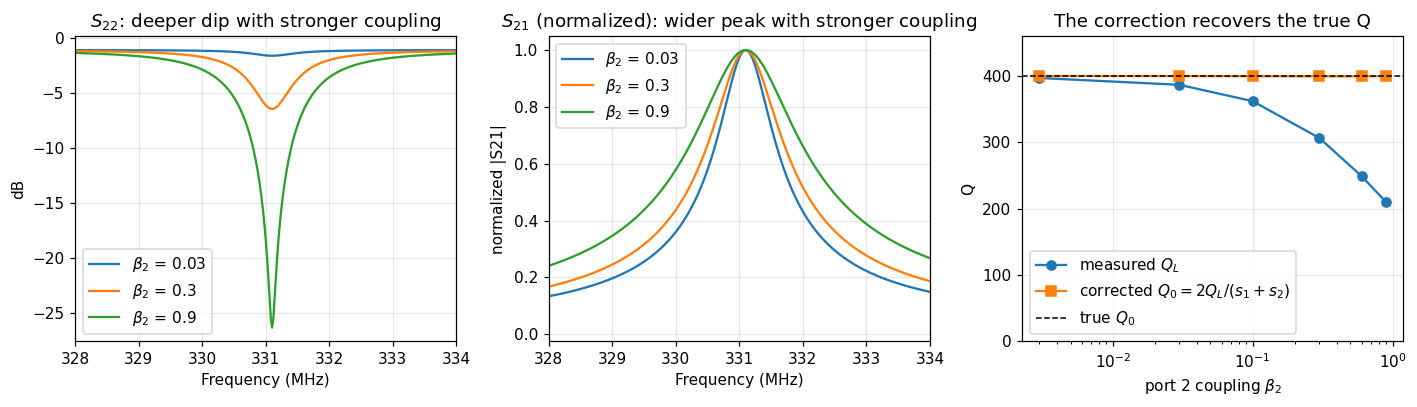

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for b2 in [0.03, 0.3, 0.9]:
    S11, S21, S22 = sparams(f, f0_true, Q0_true, 0.004, b2)
    ax[0].plot(f, 20*np.log10(abs(S22)), label=rf"$\beta_2$ = {b2}")
    ax[1].plot(f, abs(S21)/abs(S21).max(), label=rf"$\beta_2$ = {b2}")
ax[0].set_xlim(328, 334); ax[0].set_title(r"$S_{22}$: deeper dip with stronger coupling")
ax[0].set_xlabel("Frequency (MHz)"); ax[0].set_ylabel("dB"); ax[0].legend()
ax[1].set_xlim(328, 334); ax[1].set_title(r"$S_{21}$ (normalized): wider peak with stronger coupling")
ax[1].set_xlabel("Frequency (MHz)"); ax[1].set_ylabel("normalized |S21|"); ax[1].legend()

b2s  = [b for b, _ in rows]
ax[2].semilogx(b2s, [r["QL"] for _, r in rows], "o-", label=r"measured $Q_L$")
ax[2].semilogx(b2s, [r["Q0"] for _, r in rows], "s-", label=r"corrected $Q_0 = 2Q_L/(s_1+s_2)$")
ax[2].axhline(Q0_true, ls="--", c="k", lw=1, label="true $Q_0$")
ax[2].set_ylim(0, 1.15*Q0_true)
ax[2].set_title("The correction recovers the true Q")
ax[2].set_xlabel(r"port 2 coupling $\beta_2$"); ax[2].set_ylabel("Q"); ax[2].legend()
plt.tight_layout(); plt.show()

What the simulation shows:

- The flat part of each $S_{22}$ trace sits at about −1.1 dB, not 0 dB. That is cable loss. The dip must be measured **from that baseline**, not from 0 dB.
- As the dip gets deeper, the $S_{21}$ peak gets wider, even though the resonator itself has not changed.
- The raw $Q_L$ falls as coupling increases. The corrected $Q_0$ stays on the true value at every coupling strength.

## 5. Your runs

Numbers from three shielded-air runs at different loop positions.

| Run | $S_{11}$ dip | $S_{22}$ dip | $Q_L$ | Source |
|---|---|---|---|---|
| R6 (loop close) | ≈ 0 dB | ≈ 8.1 dB | ≈ 274 | read by hand from the points near the peak; the $S_{22}$ baseline is estimated |
| R3 | 0.057 dB | 5.85 dB | 269 | printed output of the testing cell in `SRR_Lab.ipynb` |
| R7 (loop pulled back) | ≈ 0.005 dB | ≈ 0.03 dB | ≈ 390 | read by hand from the points near the peak |

The next cell applies the correction to these numbers. The cell after it redoes the whole analysis from the CSV files if they are in the notebook's folder, which replaces the hand-read values with proper fits.

In [6]:
runs = [  # label, S11 dip (dB, positive), S22 dip (dB, positive), Q_L
    ("R6", 0.0,   8.1,  274.0),
    ("R3", 0.057, 5.85, 269.3),
    ("R7", 0.005, 0.03, 390.0),
]

print(f"{'run':>4s} {'Q_L':>6s} {'beta1':>7s} {'beta2':>7s} {'Q_0 (undercoupled)':>20s} {'Q_0 if port 2 overcoupled':>27s}")
for label, d1, d2, QL in runs:
    s1, s2 = 10**(-d1/20), 10**(-d2/20)
    D = 2/(s1 + s2)
    Q0_under = QL*D
    # the overcoupled reading only makes sense when port 2 shows a real dip
    Q0_over  = f"{2*QL/(s1 - s2):.0f}" if d2 > 1 else "n/a (no real dip)"
    print(f"{label:>4s} {QL:6.0f} {D*(1-s1)/2:7.4f} {D*(1-s2)/2:7.3f} {Q0_under:20.0f} {Q0_over:>27s}")

 run    Q_L   beta1   beta2   Q_0 (undercoupled)   Q_0 if port 2 overcoupled
  R6    274  0.0000   0.435                  393                         904
  R3    269  0.0044   0.326                  358                        1114
  R7    390  0.0003   0.002                  391           n/a (no real dip)


What this says:

- **The raw $Q_L$ values disagree** (about 270 with the loop close, about 390 with it pulled back) even though the resonator is the same. That difference is the loop loading, exactly as in the simulation.
- **After correction the three runs agree** to within about 10%: $Q_0 \approx 360$ to $390$. R3 is the low one. R7 needs almost no correction, so it is the most trustworthy single number.
- **The overcoupled reading is ruled out.** It would put $Q_0$ near 900 to 1100 for R6 and R3, but R7 measures about 390 directly with almost no coupling. The dip also got shallower as the loop was pulled back, which is the undercoupled signature from Step 8.

So the conclusion for the lab report is that the resonator's unloaded $Q$ is about 390. The low value compared with the paper's 2050 is a property of the resonator, not of the coupling.

In [7]:
# Full analysis from your CSV files (columns: Frequency [Hz], S11, S21, S22 in dB).
# Runs only if the files are next to this notebook.
files = ["S11_S21_S22_R3.csv", "S11_S21_S22_R6.csv", "S11_S21_S22_R7.csv"]
found = [fn for fn in files if os.path.exists(fn)]

if not found:
    print("CSV files not found in this folder. Put this notebook next to the data and re-run this cell.")
for fn in found:
    d = np.loadtxt(fn, delimiter=",", skiprows=1, usecols=(0, 1, 2, 3))
    r = analyze(d[:, 0]/1e6, d[:, 1], d[:, 2], d[:, 3], label=fn[-6:-4])
    msg = f"            beta1 = {r['beta1']:.4f}   beta2 = {r['beta2']:.4f}"
    if r['dip2_dB'] < -1:      # the overcoupled reading only makes sense for a real dip
        msg += f"   (if port 2 were overcoupled, Q_0 would be {r['Q0_if_port2_over']:.0f})"
    print(msg)

CSV files not found in this folder. Put this notebook next to the data and re-run this cell.


## 6. Practical notes

1. **Measure the dip from the baseline.** Your reflection traces sit near −1.1 dB off resonance because of cable loss. A trace that reads −7 dB at resonance has a dip of about 5.9 dB, not 7 dB.
2. **Use a wide enough span.** The baseline fit needs points well away from the resonance on both sides.
3. **The correction assumes the simple model:** one resonance, loops that couple only magnetically, and no direct loop-to-loop leakage. It works best when the correction is modest. With very deep dips the under/overcoupled ambiguity matters and you need phase data or the pull-back test.
4. **Weak coupling is still the cleanest measurement.** With both dips under about 0.5 dB, $Q_L$ is within a few percent of $Q_0$ and no correction is needed. The cost is a smaller, noisier $S_{21}$ peak. This is what the paper does: it turns the generator down until there is no detectable direct coupling.

## 7. How to put it to your TA

> A deeper $S_{22}$ dip does mean more power is going into the resonator, and that is good for signal strength. But the loop is reciprocal: the same coupling lets stored energy leak back out into the 50 Ω line, which adds a loss term, $1/Q_L = 1/Q_0 + 1/Q_{e1} + 1/Q_{e2}$. At critical coupling, where the dip is deepest, the measured $Q$ is half the true $Q$. We want the resonator's own $Q$ to compare with $r_0/\delta$, so we either couple weakly or use the dip depths to remove the port loading: $Q_0 = 2Q_L/(s_1+s_2)$. Our three runs at different loop positions give different $Q_L$ but the same $Q_0 \approx 390$ after correction.

## 8. Check yourself

1. At critical coupling on a single port, what is $|S_{11}|$ at resonance, and what is $Q_L/Q_0$?
2. In Step 6, why do the $\beta$'s cancel when you add $s_1$ and $s_2$?
3. Run R7 has almost no dip. Why does that make it the most reliable estimate of $Q_0$, and what do you give up by measuring that way?
4. You see a 6 dB dip and cannot measure phase. Describe an experiment that tells you whether the port is undercoupled or overcoupled.